In [ ]:
#Importar librerías
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pandas_datareader as pdr #Esta librería nos ayudará a leer datos de FRED
import datetime as dt #Nos ayudará a definir fechas en series de tiempo

In [ ]:
#Definir rango temporal
inicio = dt.datetime(1995, 1, 1)
fin = dt.datetime(2024,12,31)


In [ ]:
#Descargar datos de FRED
pib = pdr.DataReader('GDP', 'fred',inicio, fin)#Producto Interno Bruto EUA
desempleo = pdr.DataReader('UNRATE', 'fred', inicio, fin) #Tasa de Desempleo
ipc = pdr.DataReader('CPIAUCSL', 'fred', inicio, fin) #Índice de Precios al Consumidor

In [ ]:
#Unir en un solo DataFrame
df = pd.concat([pib, desempleo, ipc], axis=1)
df.columns = ['PIB', 'Tasa_Desempleo', 'IPC']
df.head()


,PIB,Tasa_Desempleo,IPC
DATE,,,
1995-01-01,7522.289,5.6,150.5
1995-02-01,NaN,5.4,150.9
1995-03-01,NaN,5.4,151.2
1995-04-01,7580.997,5.8,151.8
1995-05-01,NaN,5.6,152.1


In [ ]:
#Limpiar datos
df.dropna(inplace=True)
df.head()

,PIB,Tasa_Desempleo,IPC
DATE,,,
1995-01-01,7522.289,5.6,150.5
1995-04-01,7580.997,5.8,151.8
1995-07-01,7683.125,5.7,152.6
1995-10-01,7772.586,5.5,153.5
1996-01-01,7868.468,5.6,154.7


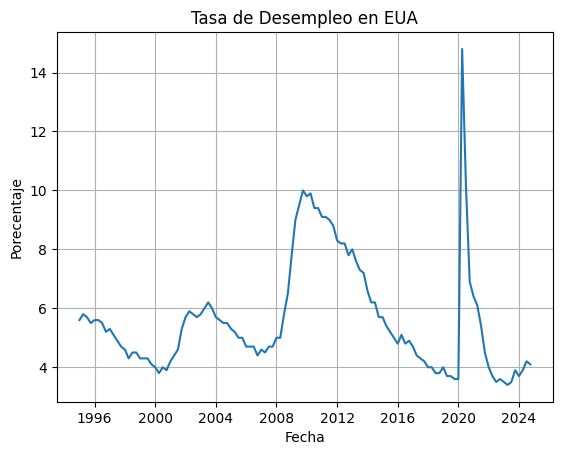

In [ ]:
#Grafico de Desempleo
plt.figure()
plt.plot(df.index, df['Tasa_Desempleo'])
plt.title('Tasa de Desempleo en EUA')
plt.xlabel('Fecha')
plt.ylabel('Porcentaje')
plt.grid()
plt.show()

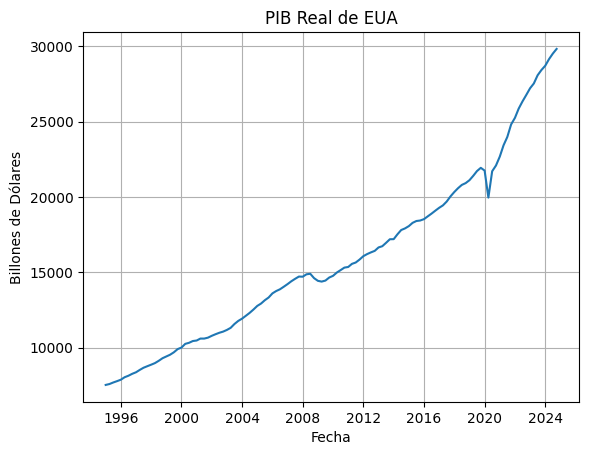

In [ ]:
#Grafico de PIB
plt.figure()
plt.plot(df.index, df['PIB'])
plt.title('PIB Real de EUA')
plt.xlabel('Fecha')
plt.ylabel('Billones de Dólares')
plt.grid()
plt.show()

In [ ]:
#Grafico de IPC
plt.figure()
plt.plot(df.index, df['IPC'])
plt.title('IPC (Índice de Precios al Consumidor) de EUA')
plt.xlabel('Fecha')
plt.ylabel('Índice')
plt.grid()
plt.show()

NameError: name 'plt' is not defined

In [ ]:
#Creando un modelo de regresión lineal PIB vs IPC
x = sm.add_constant(df['IPC']) #Se utiliza para añadir una columna a la matriz de variables predictoras (x)
reg = sm.OLS(df['PIB'], x)
modelo = reg.fit()
print(modelo.summary())


                            OLS Regression Results                            
Dep. Variable:                    PIB   R-squared:                       0.989
Model:                            OLS   Adj. R-squared:                  0.989
Method:                 Least Squares   F-statistic:                 1.041e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):          6.26e-117
Time:                        21:04:51   Log-Likelihood:                -940.81
No. Observations:                 120   AIC:                             1886.
Df Residuals:                     118   BIC:                             1891.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1.308e+04    289.855    -45.133      0.0

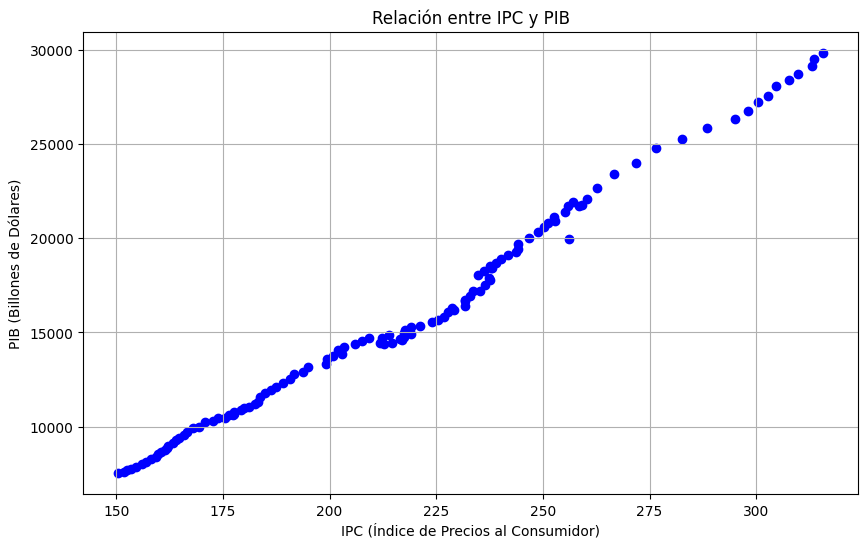

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(df['IPC'], df['PIB'], color='blue')
plt.title('Relación entre IPC y PIB')
plt.xlabel('IPC (Índice de Precios al Consumidor)')
plt.ylabel('PIB (Billones de Dólares)')
plt.grid()
plt.show()

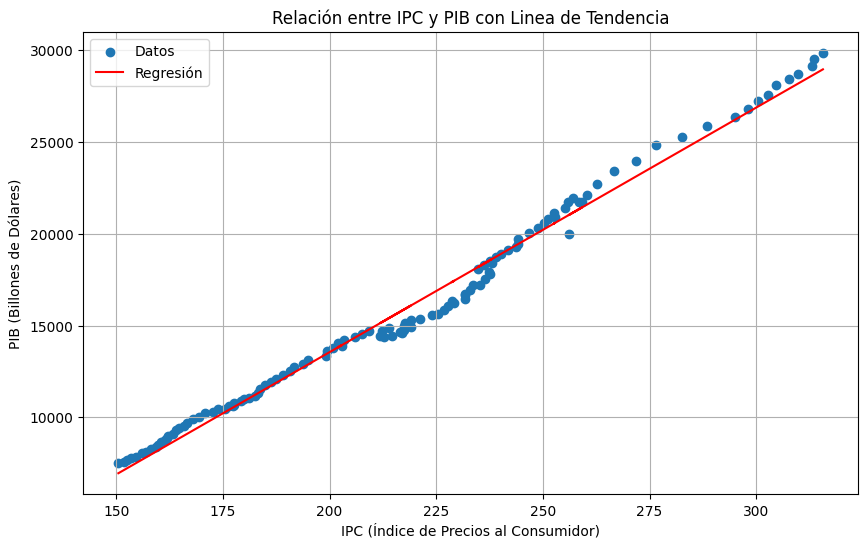

In [ ]:
#Ahora vamos a crear la gráfica del modelo de regresión lineal
plt.figure(figsize=(10,6))
plt.scatter(df['IPC'], df['PIB'], label='Datos')
plt.plot(df['IPC'], modelo.predict(x), color='red', label='Regresión')
plt.title('Relación entre IPC y PIB con Linea de Tendencia')
plt.xlabel('IPC (Índice de Precios al Consumidor)')
plt.ylabel('PIB (Billones de Dólares)')
plt.grid(True)
plt.legend()
plt.show()

La ecuación del modelo de regresión lineal es:

**$y= 133.1623x  -13080$**

**$PIB = 133.1623IPC-13080$**


Vamos a estimar o pronosticar el valor del PIB si el IPC llega a 400

In [ ]:
y= 133.1623*x-13080


In [ ]:
x= 400

In [ ]:
print(y)

40184.92
